# Punto 2 — Generación de texto a nivel de **palabra** con un Transformer tipo **Llama**

UNIVERSIDAD AUTÓNOMA DE OCCIDENTE — Inteligencia Artificial Generativa 2026-2S  
Entregable: *Modelos Generativos de Texto Basados en la Arquitectura Transformer*  
**Integrantes:** Sergio Gómez — Valeria Franco

**Objetivo:** con el mismo corpus (*Don Quijote*) y la misma arquitectura Llama del Punto 1,
modificar el pipeline para que la unidad de predicción sea la **palabra**.

### Modificaciones respecto al nivel de carácter
1. **Tokenizador de palabras**: expresión regular que separa palabras y signos de puntuación
   (`,` `.` `¿` `?` `—` y salto de línea son tokens propios, para poder generar texto bien formado).
2. **Vocabulario limitado** a las `V` palabras más frecuentes + `<unk>` (la cola larga de palabras
   raras se mapea a `<unk>`), en lugar de ~60 caracteres.
3. **Contexto** de 64 tokens (≈ 300 caracteres, más que los 128 caracteres del Punto 1).
4. **Detokenización** para reconstruir el texto a partir de tokens.
5. **Muestreo top-k** además de temperatura, para evitar palabras muy improbables.
6. Las métricas por token ya **no son comparables** con las del Punto 1; por ello se reporta además
   la **perplejidad normalizada por carácter (BPC)** para comparar ambos modelos.

In [1]:
import os, sys, re, math, time, collections
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Modo rápido (solo para pruebas locales sin GPU): RAPIDO=1 reduce corpus y épocas
RAPIDO = os.environ.get("RAPIDO", "0") == "1"
tf.random.set_seed(42); np.random.seed(42)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Corpus: *Don Quijote de la Mancha* (Miguel de Cervantes)

Reemplazamos las obras de Shakespeare por el texto completo de **Don Quijote de la Mancha**
(Proyecto Gutenberg, libro #2000, dominio público). Es un corpus en **español** de ~2 millones
de caracteres, de tamaño comparable al de Shakespeare (~1.1 M), con diálogos y narración,
lo que lo hace adecuado para un modelo de lenguaje pequeño.

In [2]:
url = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
filepath = tf.keras.utils.get_file("quijote.txt", url)
with open(filepath, encoding="utf-8") as f:
    raw = f.read()

# Quitamos la cabecera y la licencia de Gutenberg
start = raw.find("*** START OF"); start = raw.find("\n", start) + 1
end = raw.find("*** END OF")
text = raw[start:end].strip()
text = re.sub(r"\r", "", text)
text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)   # une las líneas cortadas a ~70 columnas
text = re.sub(r"\n{2,}", "\n", text)           # un salto de línea = cambio de párrafo
text = re.sub(r" {2,}", " ", text)
if RAPIDO:
    text = text[:200_000]
print(f"Caracteres: {len(text):,}")
print(text[5000:5600])

2225803/2225803 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Caracteres: 2,104,974
s los que llevaban a don Quijote
De la pendencia que don Quijote tuvo con el cabrero, con la rara aventura de los deceplinantes, a quien dio felice fin a costa de su sudor
Segunda parte del ingenioso caballero don Quijote de la Mancha
 Tasa
 Fee de erratas
 Aprobaciones
 Dedicatoria, al conde de Lemos
 Prólogo al lector
De lo que el cura y el barbero pasaron con don Quijote cerca de su enfermedad
Que trata de la notable pendencia que Sancho Panza tuvo con la sobrina y ama de don Quijote, con otros sujetos graciosos
Del ridículo razonamiento que pasó entre don Quijote, Sancho Panza y el bachill


## 2. Tokenización a nivel de palabra

In [3]:
TOKEN_RE = re.compile(r"[a-záéíóúüñ]+|\d+|\n|[^\w\s]")

def tokenize(s):
    return TOKEN_RE.findall(s.lower())

tokens = tokenize(text)
freq = collections.Counter(tokens)
VOCAB_SIZE = 4000 if RAPIDO else 12000
itos = ["<unk>"] + [w for w, _ in freq.most_common(VOCAB_SIZE - 1)]
stoi = {w: i for i, w in enumerate(itos)}
encoded = np.array([stoi.get(t, 0) for t in tokens], dtype="int32")

cover = sum(c for w, c in freq.items() if w in stoi) / len(tokens)
print(f"Tokens totales: {len(tokens):,} | tipos distintos: {len(freq):,}")
print(f"Vocabulario: {len(itos):,} | cobertura del corpus: {cover:.2%} | <unk>: {1 - cover:.2%}")
print(tokens[1000:1040])

Tokens totales: 455,987 | tipos distintos: 22,969
Vocabulario: 12,000 | cobertura del corpus: 97.59% | <unk>: 2.41%
['con', 'el', 'cabrero', ',', 'con', 'la', 'rara', 'aventura', 'de', 'los', 'deceplinantes', ',', 'a', 'quien', 'dio', 'felice', 'fin', 'a', 'costa', 'de', 'su', 'sudor', '\n', 'segunda', 'parte', 'del', 'ingenioso', 'caballero', 'don', 'quijote', 'de', 'la', 'mancha', '\n', 'tasa', '\n', 'fee', 'de', 'erratas', '\n']


In [4]:
def detokenize(toks):
    """Reconstruye texto legible: sin espacio antes de puntuación de cierre ni después de apertura."""
    out = ""
    for t in toks:
        if t == "\n":
            out += "\n"
        elif not out or out.endswith(("\n", "¿", "¡", "(", "—", "«")) or t in ",.;:!?)»":
            out += t
        else:
            out += " " + t
    return out

print(detokenize(tokens[1000:1040]))

con el cabrero, con la rara aventura de los deceplinantes, a quien dio felice fin a costa de su sudor
segunda parte del ingenioso caballero don quijote de la mancha
tasa
fee de erratas



In [5]:
def to_dataset(sequence, length, shift=1, shuffle=False, seed=None, batch_size=64):
    ds = tf.data.Dataset.from_tensor_slices(sequence)
    ds = ds.window(length + 1, shift=shift, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(length + 1))
    if shuffle:
        ds = ds.shuffle(20_000, seed=seed)
    ds = ds.batch(batch_size)
    return ds.map(lambda w: (w[:, :-1], w[:, 1:])).prefetch(tf.data.AUTOTUNE)

LENGTH = 64
n = len(encoded)
i_tr, i_va = int(n * 0.90), int(n * 0.95)
train_set = to_dataset(encoded[:i_tr], LENGTH, shift=LENGTH // 8, shuffle=True, seed=42)
valid_set = to_dataset(encoded[i_tr:i_va], LENGTH, shift=LENGTH)
test_set = to_dataset(encoded[i_va:], LENGTH, shift=LENGTH)

## 3. Arquitectura Transformer tipo Llama

El Char-Transformer de clase usa la parte **decodificadora** de un Transformer "clásico"
(GPT-2/Vaswani): embeddings posicionales aprendidos, `LayerNormalization` *post-norm*,
FFN con ReLU. La familia **Llama** (Touvron et al., 2023) introduce cuatro cambios que aquí
implementamos desde cero en Keras:

| Componente | Transformer clásico | Llama (este notebook) |
|---|---|---|
| Normalización | LayerNorm (post-norm) | **RMSNorm** (pre-norm) |
| Posición | Embedding posicional absoluto sumado | **RoPE** – rotación de *queries/keys* |
| Red feed-forward | Dense → ReLU → Dense | **SwiGLU**: `W2(SiLU(W1·x) ⊙ W3·x)` |
| Sesgos (*bias*) | Sí | **No** (todas las capas lineales sin bias) |

Además la atención es **causal** (cada posición solo ve las anteriores), por lo que el modelo
es autorregresivo: `P(x_t | x_<t)`.

Es **exactamente el mismo código** del Punto 1; solo cambia `vocab_size`.

In [6]:
import keras
from keras import layers, ops


@keras.saving.register_keras_serializable(package="llama")
class RMSNorm(layers.Layer):
    """Root Mean Square Norm: x / sqrt(mean(x^2) + eps) * g  (sin centrar ni bias)."""
    def __init__(self, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        self.scale = self.add_weight(name="scale", shape=(input_shape[-1],), initializer="ones")

    def call(self, x):
        ms = ops.mean(ops.square(x), axis=-1, keepdims=True)
        return x * ops.rsqrt(ms + self.eps) * self.scale

    def get_config(self):
        return {**super().get_config(), "eps": self.eps}


def rope(x, base=10000.0):
    """Rotary Positional Embedding. x: (batch, heads, seq, head_dim)."""
    seq_len, head_dim = ops.shape(x)[2], ops.shape(x)[3]
    half = head_dim // 2
    inv_freq = 1.0 / (base ** (ops.cast(ops.arange(half), "float32") / half))
    pos = ops.cast(ops.arange(seq_len), "float32")
    angles = ops.einsum("i,j->ij", pos, inv_freq)            # (seq, half)
    cos, sin = ops.cos(angles), ops.sin(angles)
    cos, sin = ops.cast(cos, x.dtype), ops.cast(sin, x.dtype)
    x1, x2 = x[..., :half], x[..., half:]
    return ops.concatenate([x1 * cos - x2 * sin, x1 * sin + x2 * cos], axis=-1)


@keras.saving.register_keras_serializable(package="llama")
class CausalSelfAttentionRoPE(layers.Layer):
    """Atención multi-cabeza causal con RoPE y proyecciones sin bias."""
    def __init__(self, d_model, n_heads, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.n_heads, self.dropout_rate = d_model, n_heads, dropout
        self.head_dim = d_model // n_heads
        self.wq = layers.Dense(d_model, use_bias=False)
        self.wk = layers.Dense(d_model, use_bias=False)
        self.wv = layers.Dense(d_model, use_bias=False)
        self.wo = layers.Dense(d_model, use_bias=False)
        self.drop = layers.Dropout(dropout)

    def _split(self, x, b, t):
        x = ops.reshape(x, (b, t, self.n_heads, self.head_dim))
        return ops.transpose(x, (0, 2, 1, 3))                   # (b, h, t, hd)

    def call(self, x, training=False):
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        q = rope(self._split(self.wq(x), b, t))
        k = rope(self._split(self.wk(x), b, t))
        v = self._split(self.wv(x), b, t)
        scores = ops.matmul(q, ops.transpose(k, (0, 1, 3, 2))) / ops.sqrt(ops.cast(self.head_dim, x.dtype))
        mask = ops.tril(ops.ones((t, t), dtype="bool"))          # máscara causal
        scores = ops.where(mask, scores, ops.cast(-1e9, scores.dtype))
        att = self.drop(ops.softmax(scores, axis=-1), training=training)
        out = ops.transpose(ops.matmul(att, v), (0, 2, 1, 3))
        return self.wo(ops.reshape(out, (b, t, self.d_model)))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "n_heads": self.n_heads,
                "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="llama")
class SwiGLU(layers.Layer):
    """FFN de Llama: W2( SiLU(W1 x) * W3 x ), sin bias."""
    def __init__(self, d_model, hidden, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.hidden = d_model, hidden
        self.w1 = layers.Dense(hidden, use_bias=False)
        self.w3 = layers.Dense(hidden, use_bias=False)
        self.w2 = layers.Dense(d_model, use_bias=False)

    def call(self, x):
        return self.w2(ops.silu(self.w1(x)) * self.w3(x))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "hidden": self.hidden}


@keras.saving.register_keras_serializable(package="llama")
class LlamaBlock(layers.Layer):
    """Bloque decodificador Llama (pre-norm + conexiones residuales)."""
    def __init__(self, d_model, n_heads, ffn_hidden, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.cfg = dict(d_model=d_model, n_heads=n_heads, ffn_hidden=ffn_hidden, dropout=dropout)
        self.norm1, self.norm2 = RMSNorm(), RMSNorm()
        self.attn = CausalSelfAttentionRoPE(d_model, n_heads, dropout)
        self.ffn = SwiGLU(d_model, ffn_hidden)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        x = x + self.drop(self.attn(self.norm1(x), training=training), training=training)
        x = x + self.drop(self.ffn(self.norm2(x)), training=training)
        return x

    def get_config(self):
        return {**super().get_config(), **self.cfg}


def build_llama(vocab_size, d_model=256, n_heads=8, n_layers=6, ffn_hidden=None, dropout=0.1):
    """Modelo completo: Embedding -> N x LlamaBlock -> RMSNorm -> Dense(vocab) (logits)."""
    ffn_hidden = ffn_hidden or int(8 * d_model / 3)          # proporción usada en Llama
    inputs = keras.Input(shape=(None,), dtype="int32")
    x = layers.Embedding(vocab_size, d_model)(inputs)        # sin embedding posicional: RoPE
    x = layers.Dropout(dropout)(x)
    for i in range(n_layers):
        x = LlamaBlock(d_model, n_heads, ffn_hidden, dropout, name=f"llama_block_{i}")(x)
    x = RMSNorm(name="final_norm")(x)
    logits = layers.Dense(vocab_size, use_bias=False, name="lm_head")(x)
    return keras.Model(inputs, logits, name="llama_lm")

## 4. Entrenamiento

Con un vocabulario de 12 000 palabras la capa de salida y el embedding concentran muchos
parámetros, y el corpus (~450 k tokens) es pequeño, por lo que subimos el *dropout* a 0.2 y
usamos *early stopping* para controlar el sobreajuste.

In [7]:
EPOCHS = 2 if RAPIDO else 12
cfg = dict(d_model=64, n_heads=4, n_layers=2) if RAPIDO else dict(d_model=256, n_heads=8, n_layers=4)
model = build_llama(len(itos), dropout=0.2, **cfg)

steps_per_epoch = sum(1 for _ in train_set)
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=EPOCHS * steps_per_epoch,
                                            warmup_target=5e-4, warmup_steps=min(500, steps_per_epoch))
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=0.1, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
model.summary()

callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("word_llama_quijote.keras", monitor="val_loss", save_best_only=True)]
t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS, callbacks=callbacks)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Model: "llama_lm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │     3,072,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, None, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_0 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_1 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_2 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_3 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_norm (RMSNorm)            │ (None, None, 256)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lm_head (Dense)                 │ (None, None, 12000)    │     3,072,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,289,984 (35.44 MB)

 Trainable params: 9,289,984 (35.44 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
    802/Unknown 106s 93ms/step - accuracy: 0.1111 - loss: 6.5091 - top5: 0.2601

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


802/802 ━━━━━━━━━━━━━━━━━━━━ 113s 101ms/step - accuracy: 0.1575 - loss: 5.4862 - top5: 0.3383 - val_accuracy: 0.2059 - val_loss: 4.8412 - val_top5: 0.4145
Epoch 2/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 65s 77ms/step - accuracy: 0.2369 - loss: 4.1637 - top5: 0.4646 - val_accuracy: 0.2295 - val_loss: 4.6712 - val_top5: 0.4432
Epoch 3/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 64s 76ms/step - accuracy: 0.2722 - loss: 3.6785 - top5: 0.5160 - val_accuracy: 0.2362 - val_loss: 4.7246 - val_top5: 0.4548
Epoch 4/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 65s 77ms/step - accuracy: 0.3063 - loss: 3.2966 - top5: 0.5684 - val_accuracy: 0.2324 - val_loss: 4.8579 - val_top5: 0.4529
Epoch 5/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 65s 77ms/step - accuracy: 0.3432 - loss: 2.9834 - top5: 0.6197 - val_accuracy: 0.2289 - val_loss: 5.0219 - val_top5: 0.4464
Tiempo de entrenamiento: 6.2 min


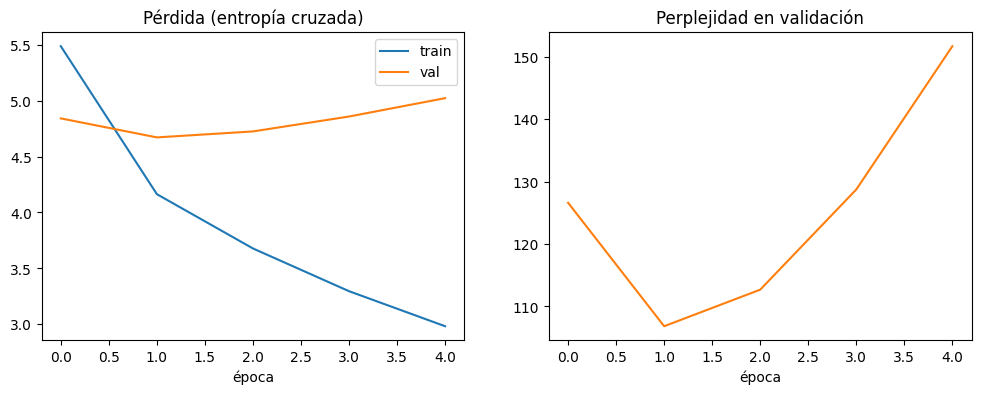

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Pérdida (entropía cruzada)"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(np.exp(history.history["val_loss"]), color="C1")
ax[1].set_title("Perplejidad en validación"); ax[1].set_xlabel("época")
plt.show()

## 5. Evaluación cuantitativa

* **Perplejidad por palabra** `PPL = e^H` en prueba, comparada con líneas base de
  **unigramas** y **bigramas** (con suavizado de Laplace).
* **Exactitud top-1 / top-5** de la siguiente palabra.
* **Tasa de `<unk>`** en prueba (cuánto texto queda fuera del vocabulario).
* **BPC equivalente** = `H_total / (n_caracteres · ln 2)`: normaliza la pérdida por carácter para
  comparar con el modelo del Punto 1 (aproximación: incluye la penalización de los `<unk>`).

In [9]:
test_loss, test_acc, test_top5 = model.evaluate(test_set, verbose=0)
test_ids = encoded[i_va:]
V = len(itos)

# Línea base de unigramas y bigramas (Laplace) estimadas en train
tr = encoded[:i_tr]
uni = np.bincount(tr, minlength=V) + 1.0; uni /= uni.sum()
h_uni = -np.mean(np.log(uni[test_ids]))
big = collections.Counter(zip(tr[:-1], tr[1:])); ctx = np.bincount(tr, minlength=V)
h_bi = -np.mean([math.log((big[(a, b)] + 1) / (ctx[a] + V)) for a, b in zip(test_ids[:-1], test_ids[1:])])

n_eval_tokens = (len(test_ids) - 1) // LENGTH * LENGTH
chars_per_token = len(detokenize([itos[i] for i in test_ids])) / len(test_ids)
bpc_equiv = test_loss / (chars_per_token * math.log(2))

print(f"{'Métrica':<26}{'Word-Llama':>12}{'Bigramas':>11}{'Unigramas':>11}")
print(f"{'Entropía cruzada (nats)':<26}{test_loss:>12.3f}{h_bi:>11.3f}{h_uni:>11.3f}")
print(f"{'Perplejidad por palabra':<26}{math.exp(test_loss):>12.1f}{math.exp(h_bi):>11.1f}{math.exp(h_uni):>11.1f}")
print(f"{'Exactitud top-1':<26}{test_acc:>12.3f}")
print(f"{'Exactitud top-5':<26}{test_top5:>12.3f}")
print(f"Tasa de <unk> en prueba: {(test_ids == 0).mean():.2%}")
print(f"BPC equivalente: {bpc_equiv:.3f}  (≈{chars_per_token:.2f} caracteres por token)")

Métrica                     Word-Llama   Bigramas  Unigramas
Entropía cruzada (nats)          4.578      6.767      6.091
Perplejidad por palabra           97.3      868.7      441.8
Exactitud top-1                  0.236
Exactitud top-5                  0.457
Tasa de <unk> en prueba: 2.56%
BPC equivalente: 1.464  (≈4.51 caracteres por token)


## 6. Generación de texto (temperatura + top-k)

En el muestreo se **prohíbe `<unk>`** y se restringe a las `k` palabras más probables.

In [10]:
def generate(prompt, n_words=120, temperature=0.8, top_k=40, seed=42):
    rng = np.random.default_rng(seed)
    ids = [stoi.get(t, 0) for t in tokenize(prompt)]
    for _ in range(n_words):
        ctx = np.array([ids[-LENGTH:]], dtype="int32")
        logits = model(ctx, training=False)[0, -1].numpy().astype("float64") / temperature
        logits[0] = -np.inf                                   # nunca generar <unk>
        top = np.argsort(logits)[-top_k:]
        p = np.exp(logits[top] - logits[top].max()); p /= p.sum()
        ids.append(int(top[rng.choice(len(top), p=p)]))
    return detokenize([itos[i] for i in ids])

prompt = "en un lugar de la mancha"
for T in [0.3, 0.8, 1.1]:
    print(f"===== Temperatura {T}, top-k 40 =====")
    print(generate(prompt, temperature=T), "\n")

===== Temperatura 0.3, top-k 40 =====
en un lugar de la mancha, que no se ha de hacer más que el que se le ha de dar a mí a mi señor don quijote, y, en tanto que yo no me ha de dar a entender que me ha de dar a mí a mi señora dulcinea del toboso, que no me ha de dar a entender que no se me ha de dar a mí el señor don quijote, y no me ha de dar a mí a mi amo, porque no me acuerdo, pues no me ha de dar a entender que no me ha de dar a mí a la señora dulcinea del toboso, y que no me ha de dar 

===== Temperatura 0.8, top-k 40 =====
en un lugar de la mancha, de la cual dio a entender que había de saber que se había de salir a mi señora dulcinea del toboso, y que fue de tan hermosa y tan gran hombre, y en qué parte no se me ha de echar de dar cuenta la vida en mi deseo.
—¿quién te dije tú, sancho? —dijo don quijote —: que aquí me ha dejado mucho que un poco momento, y el que a toda vuestra merced ha tenido por loco, y a dios me la abra su vida, y así, como lo que tengo en la corte; y si est

### Métricas sobre el texto generado

* **distinct-1 / distinct-2** y **repetición de 4-gramas** (diversidad / bucles).
* **% de bigramas vistos**: fracción de bigramas generados que aparecen en el corpus de
  entrenamiento — mide fluidez local (muy cerca de 1.0 + distinct bajo = el modelo *copia*;
  muy bajo = combinaciones agramaticales).
* **Auto-perplejidad con el modelo de bigramas**: qué tan "plausible" es el texto generado para un
  modelo independiente (menor = más fluido).

In [11]:
def distinct_n(tokens, n):
    """Proporción de n-gramas únicos (diversidad léxica; 1.0 = sin repeticiones)."""
    grams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


corpus_words = set(re.findall(r"[a-záéíóúüñ]+", text.lower()))

def valid_word_ratio(generated):
    """% de palabras generadas que existen en el vocabulario del corpus (ortografía)."""
    words = re.findall(r"[a-záéíóúüñ]+", generated.lower())
    return sum(w in corpus_words for w in words) / max(len(words), 1)


def rep_rate(tokens, n=4):
    """% de 4-gramas repetidos dentro del mismo texto (detecta bucles)."""
    return 1 - distinct_n(tokens, n)

In [12]:
train_bigrams = set(zip(tr[:-1], tr[1:]))

def gen_metrics(gen_text):
    ids = [stoi.get(t, 0) for t in tokenize(gen_text)]
    pairs = list(zip(ids[:-1], ids[1:]))
    seen = np.mean([p in train_bigrams for p in pairs])
    h = -np.mean([math.log((big[p] + 1) / (ctx[p[0]] + V)) for p in pairs])
    return seen, math.exp(h)

prompts = ["en un lugar de la mancha", "dijo sancho", "—señor caballero", "la hermosa dulcinea"]
print(f"{'T':>5}{'dist-1':>9}{'dist-2':>9}{'rep-4g':>9}{'%bigr.vistos':>14}{'PPL-bigr':>10}")
for T in [0.3, 0.8, 1.2]:
    gens = [generate(p, 100, T, seed=s)[len(p):] for s, p in enumerate(prompts)]
    toks = [w for g in gens for w in tokenize(g)]
    m = np.array([gen_metrics(g) for g in gens]).mean(axis=0)
    print(f"{T:>5}{distinct_n(toks, 1):>9.3f}{distinct_n(toks, 2):>9.3f}"
          f"{np.mean([rep_rate(tokenize(g)) for g in gens]):>9.3f}{m[0]:>14.3f}{m[1]:>10.1f}")

real = detokenize([itos[i] for i in test_ids[:400]])
rt = tokenize(real); m = gen_metrics(real)
print(f"{'real':>5}{distinct_n(rt, 1):>9.3f}{distinct_n(rt, 2):>9.3f}{rep_rate(rt):>9.3f}{m[0]:>14.3f}{m[1]:>10.1f}")

    T   dist-1   dist-2   rep-4g  %bigr.vistos  PPL-bigr
  0.3    0.168    0.316    0.214         1.000     108.2
  0.8    0.407    0.810    0.003         0.955     267.3
  1.2    0.415    0.867    0.000         0.932     403.6
 real    0.475    0.877    0.020         0.764    1203.1


## 7. Conclusiones y comparación carácter vs. palabra

Resultados obtenidos en Colab con GPU T4 (EarlyStopping detuvo el entrenamiento en la época 5 de 12
y restauró los pesos de la época 2, la de menor `val_loss` = 4.671; tiempo total 6.2 min).

| Métrica (prueba) | Word-Llama | Bigramas (Laplace) | Unigramas |
|---|---|---|---|
| Entropía cruzada (nats) | **4.578** | 6.767 | 6.091 |
| Perplejidad por palabra | **97.3** | 868.7 | 441.8 |
| Exactitud top-1 / top-5 | **0.236 / 0.457** | — | — |

| Aspecto | Nivel carácter (Punto 1) | Nivel palabra (Punto 2) |
|---|---|---|
| Vocabulario | ~60 símbolos | 12 000 palabras + `<unk>` (cobertura 97.6 %) |
| Contexto efectivo | 128 caracteres (~20 palabras) | 64 tokens (~300 caracteres) |
| BPC en prueba | 1.63 | **1.46** (equivalente, ≈4.51 caracteres por token) |
| Ortografía | Debe aprenderla (puede inventar palabras) | Garantizada (solo palabras reales) |
| Palabras raras | Siempre representables | Se pierden en `<unk>` (2.56 % en prueba) |
| Parámetros | Concentrados en los bloques | 6.1 M de 9.3 M en embedding + `lm_head` |
| Sobreajuste | Bajo | Alto: `val_loss` sube desde la época 3 |

* **El modelo de palabras supera con claridad a los n-gramas**: perplejidad 97.3 frente a 441.8
  (unigramas). El modelo de bigramas queda peor que el de unigramas porque el suavizado de Laplace
  reparte demasiada probabilidad entre 12 000² pares que casi nunca aparecen.
* **En BPC equivalente (1.46) el modelo de palabras queda por debajo del Char-Llama (1.63)**: el
  contexto de 64 palabras cubre más texto que los 128 caracteres. La comparación es aproximada,
  porque el 2.56 % de `<unk>` le ahorra al modelo de palabras predecir las palabras raras.
* **El sobreajuste es el límite principal**: la exactitud de entrenamiento sigue subiendo
  (0.34 en la época 5) mientras la de validación se estanca entre 0.23 y 0.24. Con ~450 k tokens no hay datos
  suficientes para un vocabulario de 12 000 palabras.
* **Texto generado**: a T = 0.8 no hay 4-gramas repetidos y distinct-2 = 0.81, cerca del texto real
  (0.88). A T = 0.3 aparecen bucles (21 % de 4-gramas repetidos). El 95.5 % de los bigramas
  generados a T = 0.8 ya existen en el entrenamiento, frente a 76 % en el texto real de prueba: el
  modelo tiende a recombinar frases vistas en lugar de crear combinaciones nuevas.
* El punto intermedio natural es la **tokenización por subpalabras (BPE/SentencePiece)**, que es la
  que usa Llama real: vocabulario abierto sin `<unk>` y secuencias cortas.